In [1]:
# Chạy lệnh này trong Jupyter Notebook để tự động tải lại các module đã chỉnh sửa mà không cần khởi động lại kernel
%load_ext autoreload
%autoreload 2

# import các thư viện cần thiết
import matplotlib.pyplot as plt
import torch

In [2]:
# import hàm build_data_loaders từ file data_loader.py
from data_loader import build_data_loaders

# Thiết lập các thông số
TRAIN_DIR = 'data/train'
TEST_DIR = 'data/test'
BATCH_SIZE = 64
NUM_WORKERS = 2 

# Gọi hàm
train_loader, test_loader, classes = build_data_loaders(
    TRAIN_DIR, TEST_DIR, BATCH_SIZE, NUM_WORKERS
)

print(f"Danh sách nhãn: {classes}")
print(f"Số batch tập Train: {len(train_loader)}")
print(f"Số batch tập Test: {len(test_loader)}")

Danh sách nhãn: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
Số batch tập Train: 449
Số batch tập Test: 113


Kích thước tensor ảnh: torch.Size([64, 1, 48, 48])
Kích thước tensor nhãn: torch.Size([64])


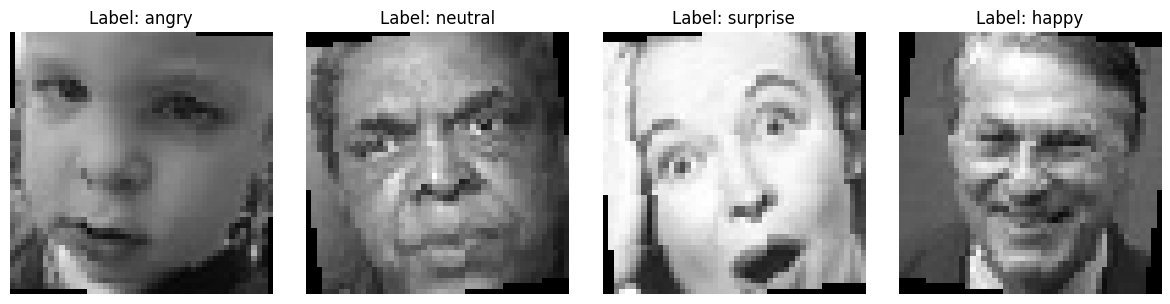

In [3]:
# Lấy một batch dữ liệu từ train_loader
images, labels = next(iter(train_loader))

print(f"Kích thước tensor ảnh: {images.shape}")
print(f"Kích thước tensor nhãn: {labels.shape}")

# Vẽ 4 ảnh đầu tiên trong batch cùng với nhãn của chúng
fig, axes = plt.subplots(1, 4, figsize=(12, 3))
for i in range(4):
    # Tensor đang ở dạng [-1, 1], cần đưa về [0, 1] hoặc un-normalize để hiển thị rõ
    img = images[i].squeeze().numpy()
    img = (img * 0.5) + 0.5 # Un-normalize (vì lúc nãy mean=0.5, std=0.5)
    
    axes[i].imshow(img, cmap='gray')
    axes[i].set_title(f"Label: {classes[labels[i]]}")
    axes[i].axis('off')

plt.tight_layout()
plt.show()

In [5]:
# Kiểm tra thiết bị và khởi tạo Mô hình
from model import EmotionCNN
import torch

# Ưu tiên dùng CUDA nếu có, nếu không thì fallback về CPU
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Đang sử dụng thiết bị: {device}")

# Khởi tạo model và đẩy lên thiết bị (GPU)
model = EmotionCNN(num_classes=7).to(device)

# Lấy lại 1 batch từ Dataloader
images, labels = next(iter(train_loader))

# Đẩy dữ liệu lên cùng thiết bị với model
images = images.to(device)
labels = labels.to(device)

# Chạy thử dữ liệu qua mạng (Forward Pass)
outputs = model(images)

print(f"Shape đầu vào (Images): {images.shape}")
print(f"Shape đầu ra (Outputs): {outputs.shape}") # Kỳ vọng: [64, 7] - (Batch_size, Num_classes)

Đang sử dụng thiết bị: cuda
Shape đầu vào (Images): torch.Size([64, 1, 48, 48])
Shape đầu ra (Outputs): torch.Size([64, 7])


In [4]:
# [Cell 4 sửa lại]
from model import ResNetEmotion # Nhớ import class mới
import torch

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Đang sử dụng thiết bị: {device}")

# Khởi tạo siêu mẫu ResNet18
model = ResNetEmotion(num_classes=7).to(device)

Đang sử dụng thiết bị: cuda


In [5]:
# Thiết lập và Chạy huấn luyện
import torch.nn as nn
import torch.optim as optim
import torch.optim.lr_scheduler as lr_scheduler
from train_engine import train_model

# Thiết lập Hàm mất mát (Loss) và Thuật toán tối ưu (Optimizer)
criterion = nn.CrossEntropyLoss()
LEARNING_RATE = 0.0001
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

# Khởi tạo Scheduler
# mode='min': Theo dõi sự giảm của Test Loss
# factor=0.5: Giảm LR đi một nửa (nhân với 0.5) khi chạm ngưỡng
# patience=2: Cho phép Loss đứng im tối đa 2 Epoch, đến Epoch thứ 3 sẽ tự giảm LR
scheduler = lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=2)

# Bắt đầu Train (Chạy thử 20 Epochs)
EPOCHS = 7
print("=== BẮT ĐẦU HUẤN LUYỆN ===")
history = train_model(
    model=model, 
    train_loader=train_loader, 
    test_loader=test_loader, 
    criterion=criterion, 
    optimizer=optimizer, 
    device=device, 
    epochs=EPOCHS,
    scheduler=scheduler
)

=== BẮT ĐẦU HUẤN LUYỆN ===


Epoch [1/7] | LR: 0.000100 | Train Loss: 1.6959 | Test Loss: 1.3058 | Test Acc: 50.17%


Epoch [2/7] | LR: 0.000100 | Train Loss: 1.3113 | Test Loss: 1.2039 | Test Acc: 53.79%


Epoch [3/7] | LR: 0.000100 | Train Loss: 1.1777 | Test Loss: 1.1025 | Test Acc: 58.28%


Epoch [4/7] | LR: 0.000100 | Train Loss: 1.0925 | Test Loss: 1.0901 | Test Acc: 59.08%


Epoch [5/7] | LR: 0.000100 | Train Loss: 1.0297 | Test Loss: 1.0457 | Test Acc: 61.16%


Epoch [6/7] | LR: 0.000100 | Train Loss: 0.9681 | Test Loss: 1.0324 | Test Acc: 61.40%


Epoch [7/7] | LR: 0.000100 | Train Loss: 0.9092 | Test Loss: 1.0437 | Test Acc: 61.69%


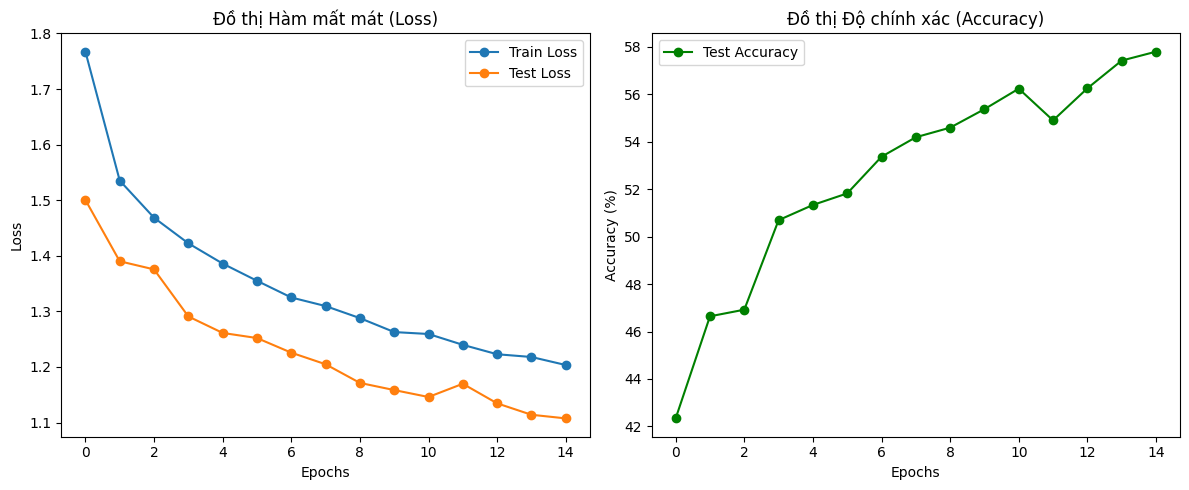

In [7]:
# Vẽ biểu đồ Loss và Accuracy
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

# Biểu đồ Loss
plt.subplot(1, 2, 1)
plt.plot(history['train_loss'], label='Train Loss', marker='o')
plt.plot(history['test_loss'], label='Test Loss', marker='o')
plt.title('Đồ thị Hàm mất mát (Loss)')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

# Biểu đồ Accuracy
plt.subplot(1, 2, 2)
plt.plot(history['test_acc'], label='Test Accuracy', color='green', marker='o')
plt.title('Đồ thị Độ chính xác (Accuracy)')
plt.xlabel('Epochs')
plt.ylabel('Accuracy (%)')
plt.legend()

plt.tight_layout()
plt.show()

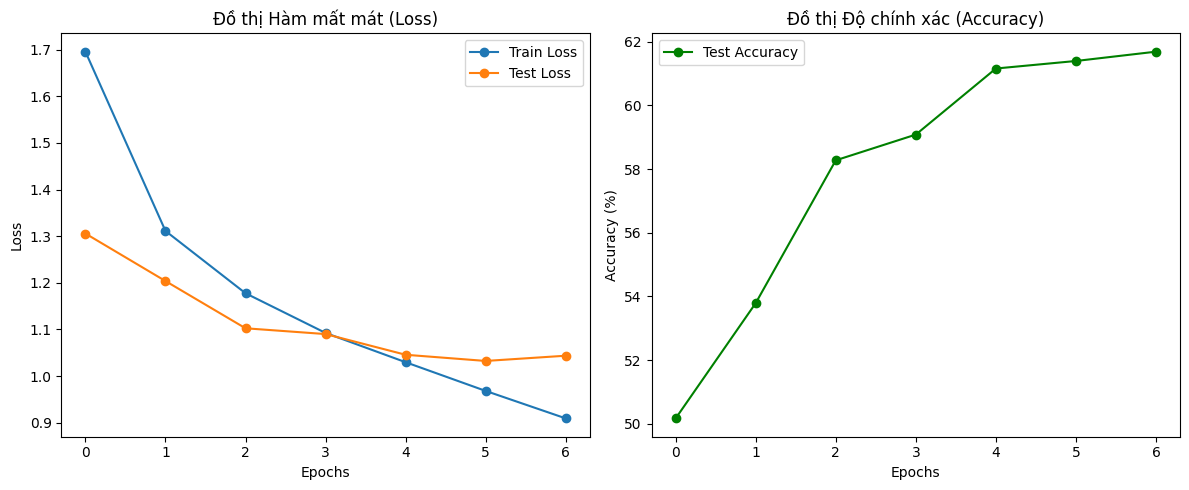

In [6]:
# Vẽ biểu đồ Loss và Accuracy
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

# Biểu đồ Loss
plt.subplot(1, 2, 1)
plt.plot(history['train_loss'], label='Train Loss', marker='o')
plt.plot(history['test_loss'], label='Test Loss', marker='o')
plt.title('Đồ thị Hàm mất mát (Loss)')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

# Biểu đồ Accuracy
plt.subplot(1, 2, 2)
plt.plot(history['test_acc'], label='Test Accuracy', color='green', marker='o')
plt.title('Đồ thị Độ chính xác (Accuracy)')
plt.xlabel('Epochs')
plt.ylabel('Accuracy (%)')
plt.legend()

plt.tight_layout()
plt.show()

In [8]:
# Lưu trọng số mô hình
import torch

MODEL_PATH = 'emotion_cnn_weights.pth'
torch.save(model.state_dict(), MODEL_PATH)
print(f"Đã lưu thành công trọng số mô hình tại: {MODEL_PATH}")

Đã lưu thành công trọng số mô hình tại: emotion_cnn_weights.pth


In [7]:
MODEL_PATH = 'resnet18_emotion_weights.pth'
torch.save(model.state_dict(), MODEL_PATH)
print(f"Đã lưu thành công trọng số mô hình tại: {MODEL_PATH}")

Đã lưu thành công trọng số mô hình tại: resnet18_emotion_weights.pth
